# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

Adapted from your existing exercise. Previous local outputs were cleared so new Colab runs provide their own evidence. 

Source: Original local package: 03_fastai/09_wearable_training_and_ethics.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '03_fastai', 'fastai', '09_wearable_training_and_ethics.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/03_fastai
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/03_fastai/results


## Full exercise evidence

- Run all exercise cells top to bottom in hosted Colab and preserve their outputs, errors and execution counts.
- Keep QUICK_RUN=False; shortened checks or synthetic replacements for real datasets do not count as full original exercises.
- Preserve plots, models, metrics and run configurations in Drive; a final-cell marker alone is insufficient.
- Complete the objective audit and supply the learner's own reflection. Synthetic data remain teaching examples.

- Worked objective answers are present as labeled learning notes; review them alongside saved coding outputs. Retain empty learner-only observations/personal reflection until supplied by the learner. Prepared prose is not hosted execution or independent recall evidence.

- Review the 18 linked-book objective ethics answers and eight labeled research analyses; supply only your own requested judgments/project/team facts and actual wearable reflection. Book additions remain separate from the discussion-based course lesson.

This cell describes evidence to collect; it does not certify completion. GPU batch caps preserve dataset coverage and epoch counts, but are documented configuration changes.

- Run the objective synthetic failed-case extraction and two 8-epoch LR fits with identical initial state, subject split, preprocessing and verified ordered batches; save actual predictions, histories, controls, checkpoints and validation-selected test evidence. Synthetic results are not real participant or personal practice evidence.


# LO2/LO4 application and data-ethics practice
Original application of the selected fast.ai pathway to the learning plan. Course links: https://course.fast.ai/Lessons/lesson1.html and https://course.fast.ai/Lessons/lesson8a.html
The ethics lesson is discussion-based; this notebook adds a practical subject-wise audit. It does not assert that the website sets this coding exercise. All wearable data are synthetic.


In [2]:
import os,json
from pathlib import Path
import numpy as np,pandas as pd,torch
import matplotlib.pyplot as plt
torch.manual_seed(42);torch.set_num_threads(1)
np.random.seed(42)
SMOKE=os.environ.get('COURSE_SMOKE','0')=='1'
results=Path('results');results.mkdir(exist_ok=True)

from fastai.tabular.all import *
from wearable_utils import *
from sklearn.metrics import f1_score,balanced_accuracy_score
x,y,subjects=make_wearable_windows();features=feature_matrix(x)
frame=pd.DataFrame(features,columns=[f'feature_{i}' for i in range(features.shape[1])]);frame['label']=y
train=np.flatnonzero(subjects<6);valid=np.flatnonzero(subjects==6);test=np.flatnonzero(subjects==7)
to=TabularPandas(frame,procs=[FillMissing,Normalize],cont_names=list(frame.columns.drop('label')),
    y_names='label',y_block=CategoryBlock(),splits=(list(train),list(valid)))
dls=to.dataloaders(bs=32,num_workers=0)
learn=tabular_learner(dls,path=Path.cwd(),model_dir='models',layers=[32,16],metrics=accuracy)
with learn.no_bar(),learn.no_logging():learn.fit_one_cycle(8,lr_max=.01)
training_log=pd.DataFrame(learn.recorder.values,columns=learn.recorder.metric_names[1:-1])
test_dl=learn.dls.test_dl(frame.iloc[test],with_labels=True)
p,truth=learn.get_preds(dl=test_dl)
report=classification_report_values(truth.numpy(),p.argmax(1).numpy());print(report)
training_log.to_csv(results/'synthetic_fastai_training.csv',index=False)
(results/'synthetic_fastai_config.json').write_text(json.dumps({'seed':42,'epochs':8,'lr_max':.01,
 'layers':[32,16],'train_subjects':list(range(6)),'valid_subjects':[6],'test_subjects':[7],
 'dataset':'synthetic','metrics':report},indent=2))
learn.export((results/'wearable_fastai.pkl').resolve())

Storage check (before_fit): artifacts 1.165 GB; configured budget 9.000 GB; additional estimate 0.034 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.165 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.165 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.165 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


...

Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.243 GB. Budget is not Drive quota.


{'macro_f1': 0.6328395061728395, 'balanced_accuracy': 0.638888888888889}


## Draft project analysis to review in your own words
Physiological signals are sensitive and emotion labels are imperfect, context-dependent observations. A model can learn participant identity, collection conditions or movement instead of the intended construct. The study should document consent and dataset conditions, retain minimal data, compare results across participants and relevant collection conditions, report uncertainty and exclusions, and avoid treating predictions as clinical findings or reliable readings of a person's internal state. Failures on unseen participants and missing sensors belong in the report.

Evidence to produce during your own study: explain one implementation choice, change a model setting and compare validation outcomes, inspect a failed prediction, and connect the result to reliability or validity. No attendance, personal reflection, badge, certificate, or repository history is manufactured by these files.


In [3]:
# Objective ethics/reliability checks; personal statements remain for the learner.
from sklearn.metrics import confusion_matrix
split_subjects={k:sorted(set(map(int,subjects[idx]))) for k,idx in [('train',train),('validation',valid),('test',test)]}
assert not set(split_subjects['train']) & set(split_subjects['validation'])
assert not set(split_subjects['train']) & set(split_subjects['test'])
assert not set(split_subjects['validation']) & set(split_subjects['test'])
ethics_audit={'dataset':'synthetic','subject_splits':split_subjects,
 'class_counts':{str(int(label)):int(np.sum(y==label)) for label in np.unique(y)},
 'nonfinite_sensor_values':int(np.sum(~np.isfinite(x))),
 'real_participant_consent_claimed':False,'clinical_validity_claimed':False,
 'reflection_completed':False}
(results/'ethics_objective_audit.json').write_text(json.dumps(ethics_audit,indent=2))
pd.DataFrame(confusion_matrix(truth.reshape(-1).numpy(),p.argmax(1).numpy())).to_csv(results/'synthetic_wearable_confusion_matrix.csv',index=False)
PERSONAL_REFLECTION = ""  #@param {type:"string"}
reflection={'learner_text':PERSONAL_REFLECTION.strip(),'completed':bool(PERSONAL_REFLECTION.strip()),
 'prompts':['Explain one privacy/consent limitation of wearable emotion data.',
 'Explain how subject identity or movement could confound evaluation.',
 'Inspect one failure and explain who might be affected.',
 'Describe one change you made and the validation evidence for it.',
 'State limits on interpretation and deployment.']}
(results/'personal_ethics_reflection.json').write_text(json.dumps(reflection,indent=2))
print('Objective split/quality audit saved. Personal reflection complete:',reflection['completed'])

Objective split/quality audit saved. Personal reflection complete: False


Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

## Authored objective extension: actual failed cases and a controlled setting change

The next cell uses the original **288 synthetic windows**, with 216 training,
36 validation and 36 test samples and the same subject split. It records an actual
baseline wrong prediction, if one exists; a perfect small synthetic test does not
justify inventing a failure. The saved input, probabilities and case record are
objective model evidence, not the learner's claimed personal inspection or real
participant harm.

Two fresh learners compare learning rates **0.01 and 0.003**, each for **8 epochs**,
layers `[32,16]` and batch size 32. The same captured initial weights, train-only
preprocessing and actual ordered batches are checked. The added comparisons keep
the last training batch (`drop_last=False`) so all 216 training rows are seen in
each epoch. They preserve the original learner/export. A fixed rule selects by
validation macro F1, then balanced accuracy, then the smaller LR; the held-out test
is used only after that rule selects a model. This is two additional full fits,
not a local smoke result or a claim of a universal improvement.

The supplied plan names **the supervisor** and the proposed project; the proposal assigns
student-led responsibilities, **Emognition primary/WESAD secondary**, subject-held-out
evaluation and planned safeguards. The saved project analysis separates these
**planned** facts from **unknown implemented** facts and **performed synthetic**
checks. Actual dataset access/terms, finalized labels/windows/use, ethics decisions
and consultation remain unknown until evidence is supplied. Personal reflection
stays blank. The course's [ethics lesson](https://course.fast.ai/Lessons/lesson8a.html)
remains separate from this custom wearable application.


### Training-history repair prepared 11 October 2026

This derived source embeds an isolated corrected copy of the objective helper. It copies and validates each complete eight-epoch training history before prediction resets fast.ai's recorder. All shared helper files remain unchanged.

The dataset, subject splits, seeds, architecture, learning rates and full fit counts are unchanged. This preparation is not execution or course completion. The previous failed notebook record and its completed-fit evidence must be retained. Run this new source in Colab to produce its own execution record.


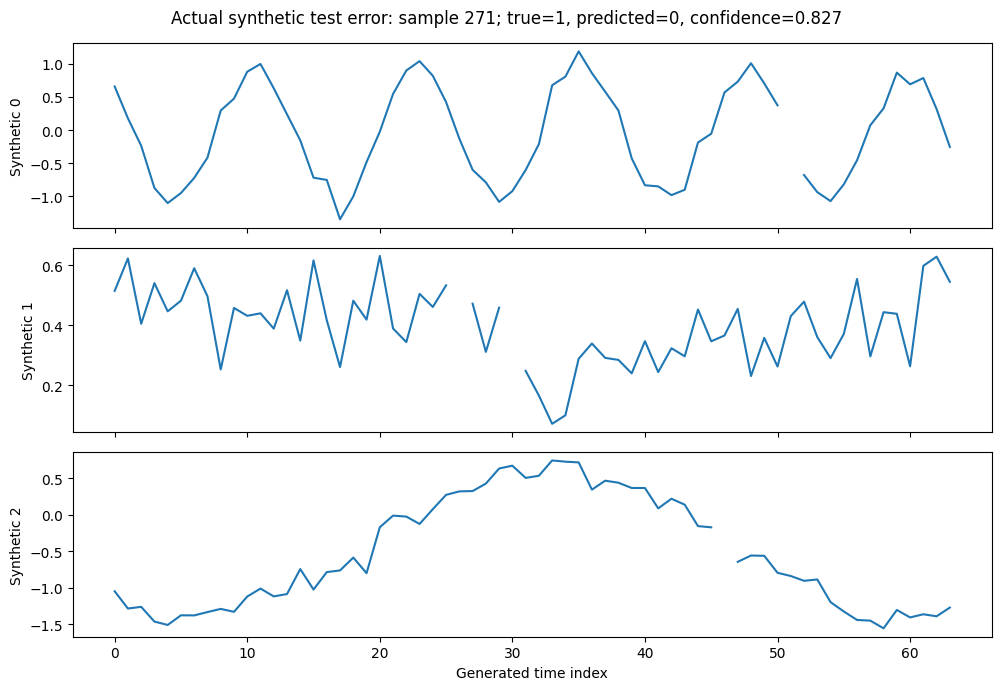

Storage check (before_fit): artifacts 1.165 GB; configured budget 9.000 GB; additional estimate 0.034 GB; runtime free 76.242 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.165 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.242 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.242 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.242 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.242 GB. Budget is not Drive quota.


...

Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.241 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.241 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.241 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.241 GB. Budget is not Drive quota.


Storage check (checkpoint_write): artifacts 1.166 GB; configured budget 9.000 GB; additional estimate 0.008 GB; runtime free 76.241 GB. Budget is not Drive quota.


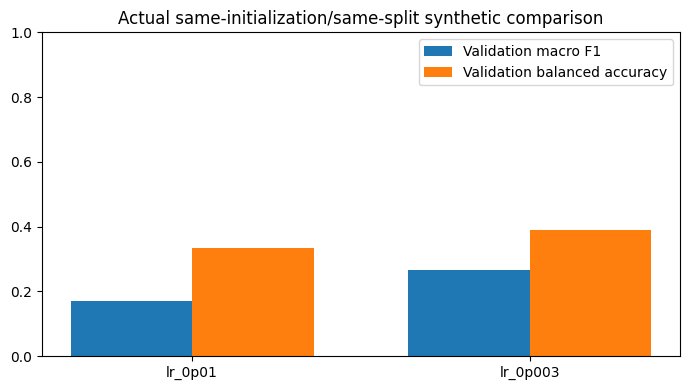

     run  validation_macro_f1  validation_balanced_accuracy  training_seconds
 lr_0p01             0.170213                      0.333333         13.007321
lr_0p003             0.266667                      0.388889         13.341706
Verified comparison controls: {'initial_state_equal': True, 'preprocessing_equal': True, 'actual_batch_order_equal': True, 'same_source_and_split': True}
Failed-case status: actual_saved_model_misclassification ; selected by validation: lr_0p003


In [4]:
# Real objective computation on the original synthetic teaching dataset.
# This derived notebook embeds its corrected helper; shared course helpers stay unchanged.
from hashlib import sha256 as _wearable_repair_sha256
_WEARABLE_REPAIR_SOURCE = '"""Objective extensions for the explicitly synthetic wearable teaching example.\n\nCalled from notebook 09 after its original fit. No personal response is supplied.\n"""\nimport copy\nimport hashlib\nimport json\nfrom pathlib import Path\nimport time\n\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport torch\n\n\ndef array_sha256(*arrays):\n    digest = hashlib.sha256()\n    for array in arrays:\n        array = np.ascontiguousarray(array)\n        digest.update(str(array.dtype).encode())\n        digest.update(json.dumps(list(array.shape)).encode())\n        digest.update(array.tobytes())\n    return digest.hexdigest()\n\n\ndef state_sha256(state):\n    digest = hashlib.sha256()\n    for key in sorted(state):\n        digest.update(key.encode())\n        digest.update(array_sha256(state[key].detach().cpu().numpy()).encode())\n    return digest.hexdigest()\n\n\ndef prediction_table(probabilities, encoded_truth, expected_labels, sample_ids, subjects, vocabulary):\n    probabilities = probabilities.detach().cpu().numpy()\n    encoded_truth = encoded_truth.detach().cpu().numpy().reshape(-1)\n    vocabulary = np.asarray([int(value) for value in vocabulary])\n    if len(np.unique(vocabulary)) != len(vocabulary):\n        raise ValueError("Class vocabulary contains duplicate labels")\n    if not (len(probabilities) == len(encoded_truth) == len(expected_labels) == len(sample_ids)):\n        raise ValueError("Prediction/sample alignment length mismatch")\n    if probabilities.ndim != 2 or probabilities.shape[1] != len(vocabulary):\n        raise ValueError("Probability/vocabulary shape mismatch")\n    if not np.isfinite(probabilities).all():\n        raise ValueError("Nonfinite probabilities")\n    if not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):\n        raise ValueError("Class probabilities do not sum to one")\n    decoded_truth = vocabulary[encoded_truth.astype(np.int64)]\n    if not np.array_equal(decoded_truth, np.asarray(expected_labels).reshape(-1)):\n        raise ValueError("Vocabulary or prediction order does not match source labels")\n    predicted = vocabulary[probabilities.argmax(axis=1)]\n    table = pd.DataFrame({"sample_id": sample_ids, "synthetic_subject_id": subjects[sample_ids],\n                          "true_class": decoded_truth, "predicted_class": predicted,\n                          "confidence": probabilities.max(axis=1), "wrong": decoded_truth != predicted})\n    for column, label in enumerate(vocabulary):\n        table[f"probability_class_{label}"] = probabilities[:, column]\n    return table\n\n\ndef _snapshot_training_history(recorder, expected_epochs=8):\n    """Copy fit records before get_preds starts a validation-only callback context."""\n    columns = list(recorder.metric_names[1:-1])\n    rows = copy.deepcopy(recorder.values)\n    if columns != ["train_loss", "valid_loss", "accuracy"]:\n        raise ValueError(f"Unexpected training history columns: {columns!r}")\n    if len(rows) != expected_epochs or any(len(row) != len(columns) for row in rows):\n        raise ValueError(f"Expected {expected_epochs} complete training epochs with {len(columns)} metrics")\n    return rows, columns\n\n\ndef run_wearable_objective_extensions(*, baseline_learner, frame, x, y, subjects,\n                                     train, valid, test, probabilities, truth, results,\n                                     quick_run=False):\n    from fastai.tabular.all import (TabularPandas, FillMissing, Normalize, CategoryBlock,\n                                   tabular_learner, accuracy, set_seed, Callback)\n    from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix\n\n    results = Path(results)\n    results.mkdir(parents=True, exist_ok=True)\n    models = Path("models")\n    models.mkdir(parents=True, exist_ok=True)\n    # These invariants describe this supplied synthetic exercise only.\n    if x.shape != (288, 64, 3) or tuple(map(len, (train, valid, test))) != (216, 36, 36):\n        raise ValueError("The full original synthetic teaching dataset/split changed")\n    source_sha = array_sha256(x, y, subjects)\n    split_sha = array_sha256(train, valid, test)\n    baseline_table = prediction_table(probabilities, truth, y[test], test, subjects, baseline_learner.dls.vocab)\n    baseline_table.to_csv(results / "wearable_baseline_test_predictions.csv", index=False)\n    wrong = baseline_table[baseline_table.wrong].sort_values(["confidence", "sample_id"], ascending=[False, True])\n    case = {"dataset": "synthetic", "selection_rule": "highest-confidence baseline test error; sample ID breaks ties",\n            "wrong_predictions": int(len(wrong)), "test_rows": 36, "input_sha256": source_sha,\n            "split_sha256": split_sha, "observed_real_participant_harm": False,\n            "learner_personal_inspection_claimed": False,\n            "hypothetical_use_risk": "An erroneous emotion label could mislead a research summary or an inappropriate downstream decision. This generated teaching sample cannot establish real participant harm or deployment validity."}\n    if len(wrong):\n        selected = wrong.iloc[0]\n        sample_id = int(selected.sample_id)\n        case.update({"status": "actual_saved_model_misclassification", "sample": selected.to_dict(),\n                     "nonfinite_sensor_values": int((~np.isfinite(x[sample_id])).sum()),\n                     "aggregate_features": frame.drop(columns="label").iloc[sample_id].to_dict()})\n        pd.DataFrame(x[sample_id], columns=["synthetic_channel_0", "synthetic_channel_1", "synthetic_channel_2"]).to_csv(\n            results / "wearable_failed_case_signal.csv", index_label="time_index")\n        fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)\n        for channel, axis in enumerate(axes):\n            axis.plot(x[sample_id, :, channel])\n            axis.set_ylabel(f"Synthetic {channel}")\n        axes[-1].set_xlabel("Generated time index")\n        fig.suptitle(f"Actual synthetic test error: sample {sample_id}; true={int(selected.true_class)}, predicted={int(selected.predicted_class)}, confidence={selected.confidence:.3f}")\n        fig.tight_layout()\n        fig.savefig(results / "wearable_failed_case_signal.png", dpi=140)\n        plt.show()\n    else:\n        case["status"] = "no_baseline_test_error_observed"\n        case["note"] = "No failed case is invented. This small synthetic test set does not establish real-world reliability."\n    (results / "wearable_failed_prediction_case.json").write_text(json.dumps(case, indent=2), encoding="utf-8")\n\n    class BatchEvidence(Callback):\n        order = 100\n\n        def before_fit(self):\n            self.epoch_hashes = {}\n            self.batch_counts = {}\n            self.row_counts = {}\n\n        def before_batch(self):\n            if not self.learn.training:\n                return\n            epoch = int(self.epoch)\n            digest = self.epoch_hashes.setdefault(epoch, hashlib.sha256())\n            for value in (*self.xb, *self.yb):\n                digest.update(array_sha256(value.detach().cpu().numpy()).encode())\n            self.batch_counts[epoch] = self.batch_counts.get(epoch, 0) + 1\n            self.row_counts[epoch] = self.row_counts.get(epoch, 0) + len(self.yb[0])\n\n        def evidence(self):\n            return [{"epoch": epoch, "training_batches": self.batch_counts[epoch],\n                     "training_rows_seen": self.row_counts[epoch],\n                     "actual_ordered_batch_sha256": self.epoch_hashes[epoch].hexdigest()}\n                    for epoch in sorted(self.epoch_hashes)]\n\n    seed = 2026\n\n    def make_dls():\n        set_seed(seed, reproducible=True)\n        table = TabularPandas(frame.copy(deep=True), procs=[FillMissing, Normalize],\n                              cont_names=list(frame.columns.drop("label")), y_names="label",\n                              y_block=CategoryBlock(), splits=(list(train), list(valid)))\n        return table.dataloaders(bs=32, num_workers=0, drop_last=False)\n\n    initial_dls = make_dls()\n    initial_learner = tabular_learner(initial_dls, path=Path.cwd(), model_dir="models", layers=[32, 16], metrics=accuracy)\n    initial_state = {key: value.detach().cpu().clone() for key, value in initial_learner.model.state_dict().items()}\n    initial_sha = state_sha256(initial_state)\n    torch.save({"state_dict": initial_state, "layers": [32, 16], "initial_sha256": initial_sha},\n               models / "wearable_controlled_initial_state.pt")\n    del initial_learner, initial_dls\n    runs = []\n    final_models = {}\n    for lr in (0.01, 0.003):\n        tag = f"lr_{str(lr).replace(\'.\', \'p\')}"\n        controlled_dls = make_dls()\n        controlled = tabular_learner(controlled_dls, path=Path.cwd(), model_dir="models", layers=[32, 16], metrics=accuracy)\n        controlled.model.load_state_dict(initial_state, strict=True)\n        loaded_sha = state_sha256(controlled.model.state_dict())\n        if loaded_sha != initial_sha:\n            raise ValueError("Initial weights/buffers differ")\n        preprocessing_sha = array_sha256(controlled_dls.train.dataset.conts.to_numpy(), controlled_dls.valid.dataset.conts.to_numpy())\n        callback = BatchEvidence()\n        set_seed(seed, reproducible=True)\n        started = time.perf_counter()\n        with controlled.no_bar(), controlled.no_logging():\n            controlled.fit_one_cycle(8, lr_max=lr, cbs=callback)\n        duration = time.perf_counter() - started\n        # get_preds resets Recorder.values to validation-only records.\n        # Persist the exact fit history while the eight training records exist.\n        training_rows, training_columns = _snapshot_training_history(controlled.recorder, expected_epochs=8)\n        pd.DataFrame(training_rows, columns=training_columns).to_csv(\n            results / f"wearable_{tag}_history.csv", index=False)\n        validation_dl = controlled.dls.test_dl(frame.iloc[valid].copy(), with_labels=True, shuffle=False, drop_last=False)\n        validation_p, validation_truth = controlled.get_preds(dl=validation_dl)\n        validation = prediction_table(validation_p, validation_truth, y[valid], valid, subjects, controlled.dls.vocab)\n        validation.to_csv(results / f"wearable_{tag}_validation_predictions.csv", index=False)\n        pd.DataFrame(confusion_matrix(validation.true_class, validation.predicted_class, labels=[0, 1, 2])).to_csv(\n            results / f"wearable_{tag}_validation_confusion.csv", index=False)\n        row = {"run": tag, "lr_max": lr, "epochs": 8, "seed": seed, "layers": [32, 16], "batch_size": 32,\n               "training_rows": 216, "validation_rows": 36, "test_rows": 36, "dataset": "synthetic",\n               "initial_state_sha256": loaded_sha, "input_sha256": source_sha, "split_sha256": split_sha,\n               "preprocessed_train_validation_sha256": preprocessing_sha,\n               "validation_macro_f1": float(f1_score(validation.true_class, validation.predicted_class, average="macro", labels=[0, 1, 2], zero_division=0)),\n               "validation_balanced_accuracy": float(balanced_accuracy_score(validation.true_class, validation.predicted_class)),\n               "training_seconds": duration, "actual_batch_order": callback.evidence(), "quick_run": bool(quick_run)}\n        controlled.save(f"wearable_controlled_{tag}", with_opt=True)\n        runs.append(row)\n        final_models[tag] = controlled\n        (results / f"wearable_{tag}_configuration.json").write_text(json.dumps(row, indent=2), encoding="utf-8")\n    controls = {"initial_state_equal": runs[0]["initial_state_sha256"] == runs[1]["initial_state_sha256"],\n                "preprocessing_equal": runs[0]["preprocessed_train_validation_sha256"] == runs[1]["preprocessed_train_validation_sha256"],\n                "actual_batch_order_equal": runs[0]["actual_batch_order"] == runs[1]["actual_batch_order"],\n                "same_source_and_split": all(r["input_sha256"] == source_sha and r["split_sha256"] == split_sha for r in runs)}\n    if not all(controls.values()) or any(len(r["actual_batch_order"]) != 8 or\n            any(epoch["training_rows_seen"] != 216 for epoch in r["actual_batch_order"]) for r in runs):\n        (results / "wearable_controlled_comparison_incomplete.json").write_text(json.dumps({"runs": runs, "controls": controls}, indent=2), encoding="utf-8")\n        raise ValueError("The controlled comparison failed an actual control check; inspect saved run evidence")\n    # Fixed rule: use validation macro F1, then balanced accuracy, then smaller LR.\n    selected = sorted(runs, key=lambda r: (-r["validation_macro_f1"], -r["validation_balanced_accuracy"], r["lr_max"]))[0]\n    selected_learner = final_models[selected["run"]]\n    selected_test_dl = selected_learner.dls.test_dl(frame.iloc[test].copy(), with_labels=True, shuffle=False, drop_last=False)\n    selected_p, selected_truth = selected_learner.get_preds(dl=selected_test_dl)\n    selected_test = prediction_table(selected_p, selected_truth, y[test], test, subjects, selected_learner.dls.vocab)\n    selected_test.to_csv(results / "wearable_validation_selected_test_predictions.csv", index=False)\n    concise = pd.DataFrame([{k: v for k, v in row.items() if k != "actual_batch_order"} for row in runs])\n    concise.to_csv(results / "wearable_controlled_validation_comparison.csv", index=False)\n    fig, axis = plt.subplots(figsize=(7, 4))\n    locations = np.arange(len(concise))\n    axis.bar(locations - .18, concise.validation_macro_f1, .36, label="Validation macro F1")\n    axis.bar(locations + .18, concise.validation_balanced_accuracy, .36, label="Validation balanced accuracy")\n    axis.set_xticks(locations, concise.run)\n    axis.set_ylim(0, 1)\n    axis.legend()\n    axis.set_title("Actual same-initialization/same-split synthetic comparison")\n    fig.tight_layout()\n    fig.savefig(results / "wearable_controlled_validation_comparison.png", dpi=140)\n    plt.show()\n    evidence = {"dataset": "synthetic", "runs": runs, "verified_controls": controls,\n                "selection_rule": "validation macro F1, balanced accuracy, then smaller LR; no test tuning",\n                "selected_run": selected["run"],\n                "observed_validation_macro_f1_lr_0p003_minus_0p01": runs[1]["validation_macro_f1"] - runs[0]["validation_macro_f1"],\n                "selected_test_macro_f1": float(f1_score(selected_test.true_class, selected_test.predicted_class, average="macro", labels=[0, 1, 2], zero_division=0)),\n                "selected_test_balanced_accuracy": float(balanced_accuracy_score(selected_test.true_class, selected_test.predicted_class)),\n                "objective_computations_observed": True, "learner_personal_setting_change_claimed": False,\n                "learner_personal_reflection_completed": False, "real_dataset_or_clinical_validity_claimed": False,\n                "provider_course_completion_claimed": False, "quick_run": bool(quick_run),\n                "limitations": "Two learning rates, one synthetic split and initialization; no independent evidence about real participant emotion, real-world harm or general superiority."}\n    (results / "wearable_controlled_comparison_evidence.json").write_text(json.dumps(evidence, indent=2), encoding="utf-8")\n    project = {"document_status": "Documented proposal/plan; intended facts, not proof of implementation",\n               "planned": {"student": "Learner", "supervisor_from_learning_plan": "the supervisor",\n                           "project": "Benchmark replication and robust improvement of wearable physiological emotion recognition",\n                           "primary_dataset": "Emognition", "secondary_dataset": "WESAD",\n                           "responsibility": "Student-led research with planned supervisor review/feedback",\n                           "evaluation": "Subject-held-out/LOSO, training-subject validation and training-only normalization",\n                           "safeguards": "Verify dataset terms; no new recruitment/video; secure secondary wearable/self-report data; confirm applicable ethics review/exemption with supervisor"},\n               "unknown_actual_facts": ["Original data access and terms reviewed/accepted", "Final labels/windows/use and included subjects", "Actual ethics decision/storage safeguards", "Real team involvement and perspectives consulted or missing"],\n               "performed_in_this_synthetic_notebook": {"dataset": "generated synthetic teaching data", "split_subjects": {"train": list(range(6)), "validation": [6], "test": [7]}, "objective_failure_record": case["status"], "controlled_validation_comparison": controls},\n               "candidate_analysis": "Use the intended research question of predicting specified annotations across unseen participants, with leakage/error audits and uncertainty. For the intended student-led project, supervisor/domain/affected-user consultation could uncover missing collection conditions or harmful interpretations; actual consultation must be supplied by the learner.",\n               "sources": {"learning_plan": "unpublished learning plan, pages 1–5", "proposal": "unpublished research proposal, dataset/method/ethics/responsibility sections"},\n               "learner_personal_opinion_or_consultation_fabricated": False}\n    (results / "wearable_project_analysis_planned_unknown_performed.json").write_text(json.dumps(project, indent=2), encoding="utf-8")\n    print(concise[["run", "validation_macro_f1", "validation_balanced_accuracy", "training_seconds"]].to_string(index=False))\n    print("Verified comparison controls:", controls)\n    print("Failed-case status:", case["status"], "; selected by validation:", selected["run"])\n    return {"case": case, "comparison": evidence, "project_analysis": project}\n'
_WEARABLE_REPAIR_SOURCE_SHA256 = '83fbc46191323840518a5709c4851589f15edd98ad1f4d968774d291c39650f5'
assert _wearable_repair_sha256(_WEARABLE_REPAIR_SOURCE.encode('utf-8')).hexdigest() == _WEARABLE_REPAIR_SOURCE_SHA256
_wearable_repair_namespace = {'__name__': 'wearable_objective_extension_embedded_20261011'}
exec(compile(_WEARABLE_REPAIR_SOURCE, '<wearable_objective_extension_embedded_20261011>', 'exec'), _wearable_repair_namespace)
wearable_objective_results = _wearable_repair_namespace['run_wearable_objective_extensions'](
    baseline_learner=learn, frame=frame, x=x, y=y, subjects=subjects,
    train=train, valid=valid, test=test, probabilities=p, truth=truth,
    results=results, quick_run=QUICK_RUN)


In [5]:
finish_run(COLAB_CONTEXT)

Saved run settings. Save the notebook in Colab to keep its cell outputs.


## Worked objective ethics notes — separate from personal reflection

This is the prepared synthetic wearable application associated with the course's
ethics discussion, not an official website coding exercise. The five prompts in
`reflection['prompts']` are retained, and `PERSONAL_REFLECTION` remains empty.

**Prompt 1 — privacy and consent.** Physiological readings can expose sensitive
information beyond the intended emotion label, including identity-linked patterns.
Consent for collection does not by itself establish permission for every later use.
A study should state the intended use, access, retention and limitations; synthetic
teaching records provide no evidence of real participant consent.

**Prompt 2 — confounding and evaluation.** If windows from one person appear in
both training and evaluation, person-specific baselines can make the score optimistic
for unseen people. Movement can affect signals and correlate with labels. Keep people
disjoint, then check performance by person and movement condition where those
annotations exist. The `split_subjects` assertions test disjointness; the synthetic
confusion matrix measures this teaching example, not real-world validity.

**Prompt 5 — interpretation limits.** A classification score is conditional on the
training data and labels. It does not establish a person's internal emotional state
or suitability for clinical or employment decisions. State uncertainty, sensor
limitations and evaluation population. A synthetic example cannot establish
deployment performance.

These points apply the course's discussion of privacy, feedback, bias and responsible
project design. [fast.ai ethics lesson](https://course.fast.ai/Lessons/lesson8a.html),
[source ethics chapter](https://github.com/fastai/fastbook/blob/master/03_ethics.ipynb).

**Prompt 3 — learner's observed failure: __________.** After execution, select an
actual off-diagonal confusion-matrix case; examine its input, true/predicted label
and confidence. Record who could be affected in the intended study context. No
case inspection or personal observation is asserted by these notes.

**Prompt 4 — learner's actual change and validation evidence: __________.** Record
one setting you change, hold the evaluation split fixed, and compare saved outcomes.
Describe your reasoning and what the data support. No change or improved outcome
is asserted here; the original personal-reflection field stays blank.

## Authored additions: the linked ethics chapter's objective questionnaire

The course ethics lesson, this custom synthetic wearable audit, and the linked book chapter are separate materials. The following notes answer the 18 objective questionnaire topics in the [pinned chapter 3 source](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb), original cell 104 (one-based). They are worked learning notes, not personal opinions, independent recall, attendance or provider completion evidence. Historical examples refer to the chapter's period, not a claim about every current product.

1. **Ethical answers.** Ethics involves justified standards and reasoning about stakeholders and context, rather than a universal checklist of automatically correct decisions. [Markkula's explanation](https://www.scu.edu/ethics/ethics-resources/ethical-decision-making/what-is-ethics/).
2. **Different backgrounds.** People with different experiences can identify affected groups, assumptions and harms that one team overlooks. Consultation needs meaningful participation; simply counting demographic categories does not establish that concerns were heard. [Ethical Toolkit](https://www.scu.edu/ethics-in-technology-practice/ethical-toolkit/).
3. **IBM example.** The chapter connects tabulation/support for Nazi persecution to company profit incentives and employees' technical duties and obedience. This is its historical account, not proof of every individual's motive. [Chapter source](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb).
4. **Volkswagen example.** James Robert Liang was a diesel-development engineer involved in implementing emissions-test cheating software. Technical participation, rather than holding an executive title, was sufficient for his role in the criminal case. [2017 Justice Department statement](https://www.justice.gov/usao-edmi/pr/volkswagen-engineer-sentenced-his-role-conspiracy-cheat-us-emissions-tests).
5. **Gang database.** California's audit found unsupported or inaccurate CalGang records and deficient oversight. Birthdates suggested 42 entries were younger than one year when entered; 28 supposedly admitted membership. This demonstrates unreliable records and accountability failures, rather than proof that those infants were gang members. [California State Auditor](https://information.auditor.ca.gov/reports/2015-130/summary.html).
6. **Harmful recommendations.** Learned viewing associations and engagement incentives can reinforce harmful exposure without an explicit programmed instruction. This explains the chapter's case, not today's algorithm. [Chapter source](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb).
7. **Central metrics.** A convenient objective can be an imperfect proxy for the intended benefit. Optimizing it can overlook subgroups, unintended consequences and changes caused by deployment. Report relevant error types and outcomes, and examine the data-generating and decision processes, rather than treating one aggregate score as a complete ethical assessment. [Suresh and Guttag, version 2](https://arxiv.org/pdf/1901.10002v2).
8. **Meetup example.** Gender was excluded to avoid recommendations reducing women's attendance and reinforcing that reduction. Correlated proxies mean excluding one feature does not itself guarantee fairness. [Chapter source](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb).
9. **The six source types.** The chapter-era framework distinguishes historical, representation, measurement, aggregation, evaluation and deployment bias. Respectively, these concern inequities already present in the world; inadequate coverage of parts of the population; misleading proxy measurements; inappropriate pooling of differing groups; unsuitable evaluation data/metrics; and mismatched real-world use or interpretation. This is the six-category version; later paper revisions extend the taxonomy. [2020 version 2](https://arxiv.org/pdf/1901.10002v2), [later revision](https://arxiv.org/abs/1901.10002).
10. **Two US examples.** A resume field experiment found fewer callbacks for otherwise comparable applications assigned Black-associated names. A separate online-ad study found arrest-suggestive advertisements disproportionately associated with searches for Black-associated names, including searches unrelated to an actual arrest record. These are documented historical studies, not present-day prevalence estimates. [Bertrand and Mullainathan](https://www.nber.org/papers/w9873.pdf), [Sweeney](https://arxiv.org/abs/1301.6822).
11. **Image geography.** The cited ImageNet study found heavy US and Western-country representation and differing performance across locales. That historic geographic imbalance limits inference about images from underrepresented settings; it is not evidence about the provenance of every later image dataset. [Shankar and colleagues](https://arxiv.org/abs/1711.08536).
12. **Sinusitis and recorded stroke.** The paper predicts recorded diagnoses, which depend on symptoms, seeking care, testing and diagnosis. A sinusitis record can proxy for healthcare use instead of a biological cause of stroke. A predictive association with that measured label is therefore not evidence that sinusitis causes stroke. [Mullainathan and Obermeyer](https://pmc.ncbi.nlm.nih.gov/articles/PMC5540263/).
13. **Representation bias.** Important regions or groups of the intended population have too little relevant training coverage. A dataset can underrepresent a minority even when sampled proportionally to a population. More representative data can address this source, but do not automatically repair flawed labels or inequities already encoded in the world. [Suresh and Guttag](https://arxiv.org/pdf/1901.10002v2).
14. **Human and automated decisions.** Both can be biased. Automation adds scale, feedback and apparent objectivity. Genuine review and appeals need deliberate design; an available override alone does not establish them. [Chapter source](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb).
15. **Disinformation.** It can combine truths, misleading context and falsehoods to produce distrust or confusion, extending beyond fabricated news. [Chapter source](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb).
16. **Generated text.** Plausible messages can be produced cheaply at scale, making coordinated influence resemble independent participation. This risk does not make all generated text deceptive. [Chapter discussion](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb).
17. **Five chapter-era lenses.** Rights concerns affected people's rights; justice concerns fair treatment; utility weighs benefits and harms; common good examines shared community conditions; virtue examines the character expressed by an action. The source chapter uses these five. Markkula's newer framework additionally identifies a care-ethics lens. [Original five approaches](https://www.scu.edu/ethics/ethics-resources/ethical-decision-making/thinking-ethically/), [updated framework](https://www.scu.edu/ethics/ethics-resources/a-framework-for-ethical-decision-making/).
18. **Policy's role.** Organization or public policy can establish responsibilities, documentation, access limits, review and recourse when individual modeling choices cannot address institutional incentives or shared harms. Technical fixes and policies should be evaluated together. This is a design argument, not a statement of applicable legal obligations. [Ethical Toolkit](https://www.scu.edu/ethics-in-technology-practice/ethical-toolkit/).


## Authored research notes and learner-owned judgments

These additions map the eight further-research prompts in the [same chapter](https://github.com/fastai/fastbook/blob/4aefe0a9050d9894255a878c7d72c04458d60de8/03_ethics.ipynb), original cell 106 (one-based). The analyses are prepared examples; a request for your judgment, actual project facts or team experience remains blank.

**1 — Healthcare allocation.** The article describes care reductions, implementation defects and difficulty understanding or contesting the allocation process. [Assigned article](https://www.theverge.com/2018/3/21/17144260/healthcare-medicaid-algorithm-arkansas-cerebral-palsy). A prevention design would version and independently check the implemented rules against the approved specification, test documented disability cases, audit major changes before cutting services, publish understandable individual explanations, assign a responsible owner, and provide prompt human correction and interim support during disputed cases. These are proposed controls, not a claim that testing alone fixes an inadequate care budget or that the reader already performed an audit.

**2 — Recommendations and feedback.** Google's published historical system learns candidate selection and ranking from viewing behavior. Recommendations can change later behavior, so the future training distribution is partly created by the system itself. [2016 Google Research paper](https://research.google.com/pubs/archive/45530.pdf). A feedback loop is not mathematically destined to be harmful: outcome depends on objectives, constraints and context. Candidate safeguards include child-safety exclusions, diversity of exposure, independent safety evaluation, user controls, and evaluating longer-term outcomes rather than only engagement. Public oversight could require auditable risk controls and meaningful recourse; this is a proposed approach, not a legal conclusion. **Your judgment about the appropriate company/government response: __________.**

**3 — Ad discrimination.** Sweeney's study documents unequal arrest-suggestive ad delivery associated with racialized names; it does not by itself identify the precise contribution of each advertiser, algorithmic choice and user interaction. [Assigned paper](https://arxiv.org/abs/1301.6822). An objective response would investigate ad-selection and optimization logs, measure disparate outcomes, remove unsupported arrest implications, test remedial changes and make correction available. Responsibilities can be shared without allowing each participant to assume another will solve the harm. **Your judgment about responsibility and the appropriate response: __________.**

**4 — Cross-disciplinary teams.** Domain experts can question whether a label measures the intended construct; engineers can examine implementation; social researchers and affected users can identify missing groups and harmful use; governance specialists can test accountability and recourse. Differences help when the team has time, authority and a process to act on concerns, not merely different job titles. [Ethical Toolkit](https://www.scu.edu/ethics-in-technology-practice/ethical-toolkit/).

**5 — Moral hazard and measurement.** A model may accurately reproduce recorded medical decisions while learning systematic measurement error or incentives rather than the intended condition. The authors argue for taking data generation seriously and evaluating tools against meaningful outcomes. [Assigned paper, available full text](https://pmc.ncbi.nlm.nih.gov/articles/PMC5540263/). Candidate actions are to document label generation, inspect whether healthcare use is a proxy, compare against less behavior-dependent outcomes where feasible, and evaluate prospectively before using the predictions to allocate treatment. Removing sinusitis alone would not remove every correlated proxy. **Your preferred actions and reasons: __________.**

**6 — Authentication and forgery.** Etzioni proposes authenticating digital content with signatures. [Assigned article](https://hbr.org/2019/03/how-will-we-prevent-ai-based-forgery). As a technical inference, a valid signature can support origin/integrity under its trust assumptions; it cannot establish that the signed claim is true. Adoption, signing-key security, revoked credentials and handling unsigned genuine content matter. Distinguish altered content from authentic but misleading context. **Your judgment about whether the proposal is workable, with reasons: __________.**

**7 — Your wearable-emotion project.** A defensible research question could be whether specified physiological measurements predict specified annotations across unseen participants under documented collection conditions. That is narrower than reading a person's internal emotional state. The existing synthetic notebook illustrates a subject-disjoint split and a baseline comparison; it cannot establish consent, real subgroup fairness or real-world validity.

Before making claims about your actual project, record: intended research use and prohibited uses; the real data's provenance, permitted use and label process; population/conditions and missing groups; access and retention; auditability of preprocessing, splits and exclusions; baseline and subgroup error evidence; uncertainty; correction/withdrawal/appeal mechanisms where relevant; and whose perspectives were consulted. **Your actual dataset/population, intended decision, current safeguards and unresolved limitations: __________.** These facts cannot be supplied by synthetic training or inferred from a learning plan alone.

**8 — Actual team and consultation.** Role, lived experience and relevant domain knowledge can all affect what a project overlooks. For a solo learning project, consultation can widen the perspectives considered even though there is no team to count. This is a possible process, not a claim that you have consulted anyone. **Your actual team/consultation context, any missing perspectives, and one feasible improvement: __________.**

Keep the existing `PERSONAL_REFLECTION` field empty until you supply your own response. The five custom wearable prompts, the book's objective questionnaire and these research notes remain separately identified.


In [6]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null, "base_model_commit": null, "fastai_reuse_evidence": {"contract_version": 1, "notebook": "03_fastai/09_wearable_training_and_ethics.ipynb", "source_sha256": "3a41ead7901380f32bb01e4c6c29c60f9ec345182488159f86ef3905efb71463", "helper_sha256": {"03_fastai/convolution_workbook_exercise.py": "ecacb93aef6846c82d6a9eebc4809e1a6766410f04783ac132f247935af3a8fc", "03_fastai/fastai_utils.py": "a03e913e1c07f55aedd56ee6128096f3f952f4f8be22f83c4a22002589c4bd18", "03_fastai/wearable_objective_extension.py": "f9b0a8bf81a5bab8c10aee5e8795e9cef3df58e40925f7705e58301b18b3fbe9", "03_fastai/wearable_utils.py": "6de4ee45118d96e024bd4e0f3fd3552905b38a1ff01c0a5146578bb0d8263db9", "colab_runtime.py": "e11bedb13e1bd71a71c01cc49e558d05c89b057259fe52e64301d0c4d626a140", "course_persistence.py": "f14f7282d4b1e718b01858a61a2dca8b60f5135ba9971fc7923c50bf12cca3d2"}, "persistent_cours